## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00358ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.29s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_attn 1.2 [77725860|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_attn 1.2 [77725860|fa6007dd3ce42e6d]'
00: ====================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attn 07470e29/.
00: Launching 'AEC train_vol_vol_attn 1.2 [77725860|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 10 batches per epoch, and a batch size of 256 for valuation.
01:   This model has 40977 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_attn' epoch 1/1000 error avg trn 1001; val 662.2/1403 [4s 0.7s 0.35s]. LR: 1.00e-03, GN 471.2, excess_weighted: 0.06162/0.07169, excess_weighted_avg: 0.05971/0.07154, excess_spread: 897.5/1486, excess_spread_avg: 848.1/1486, excess: 0.0759/0.09275, 

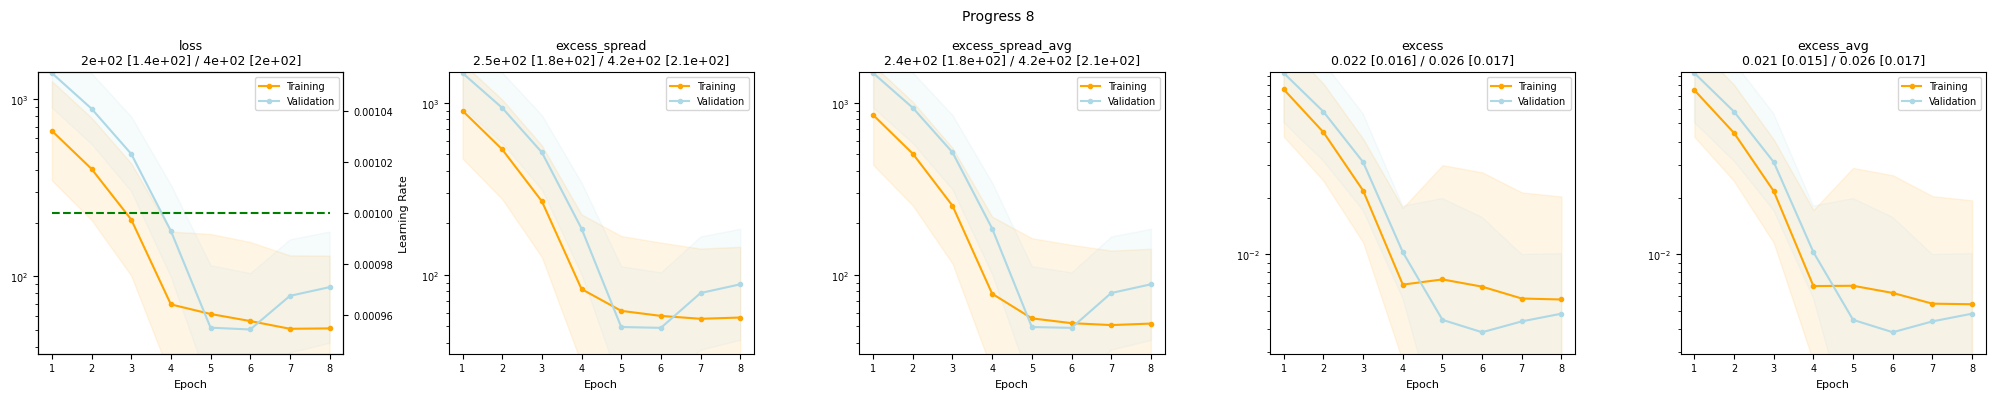

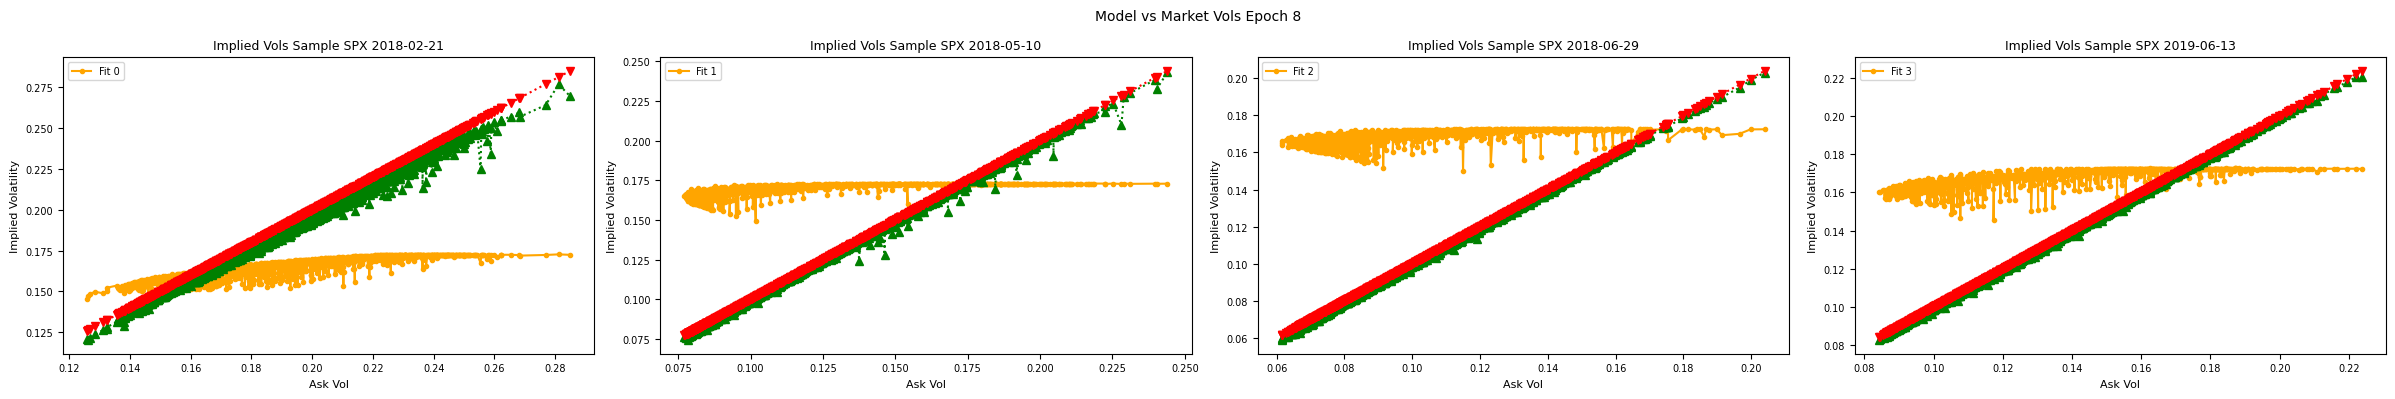

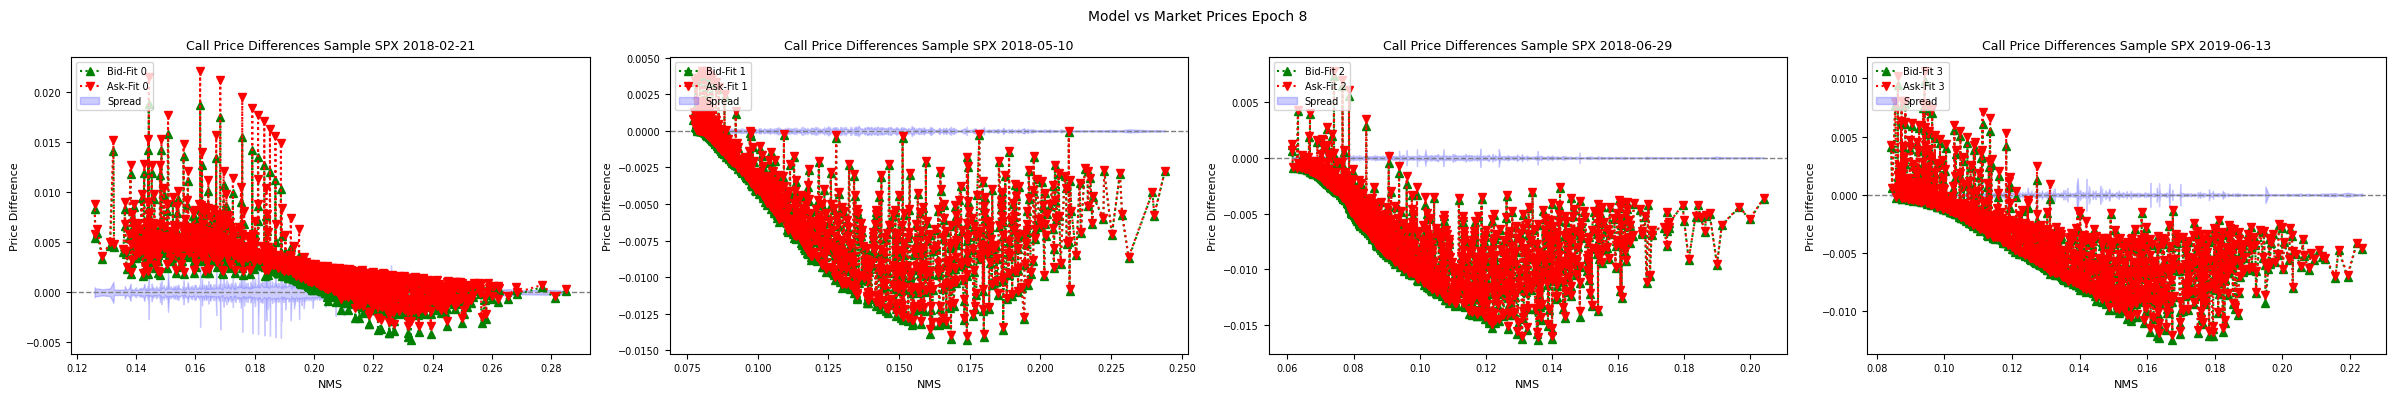

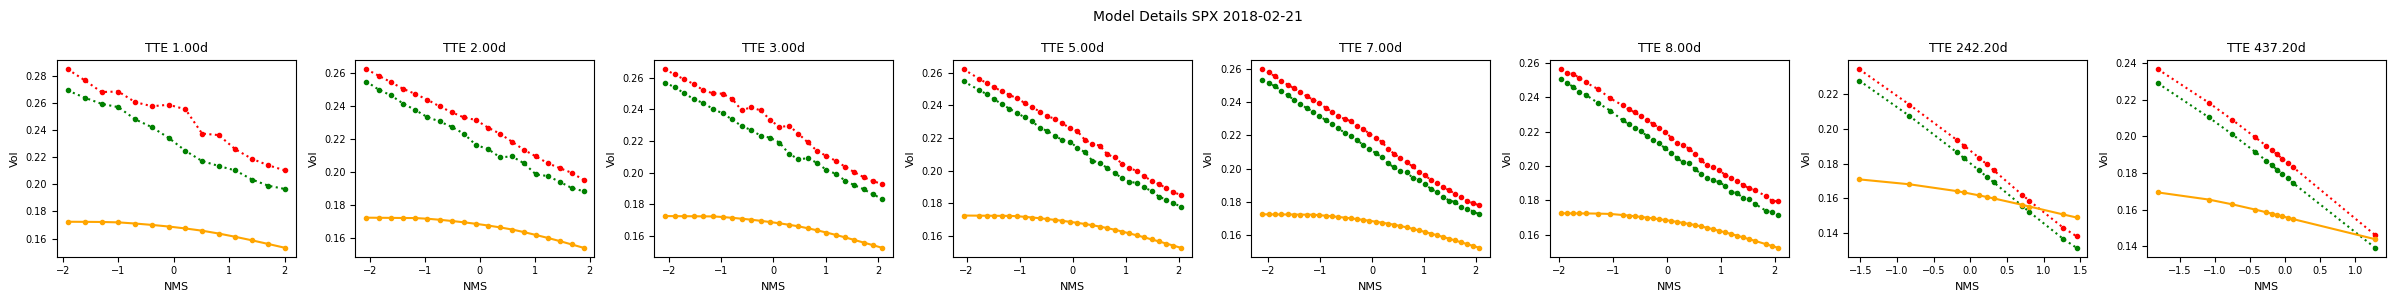

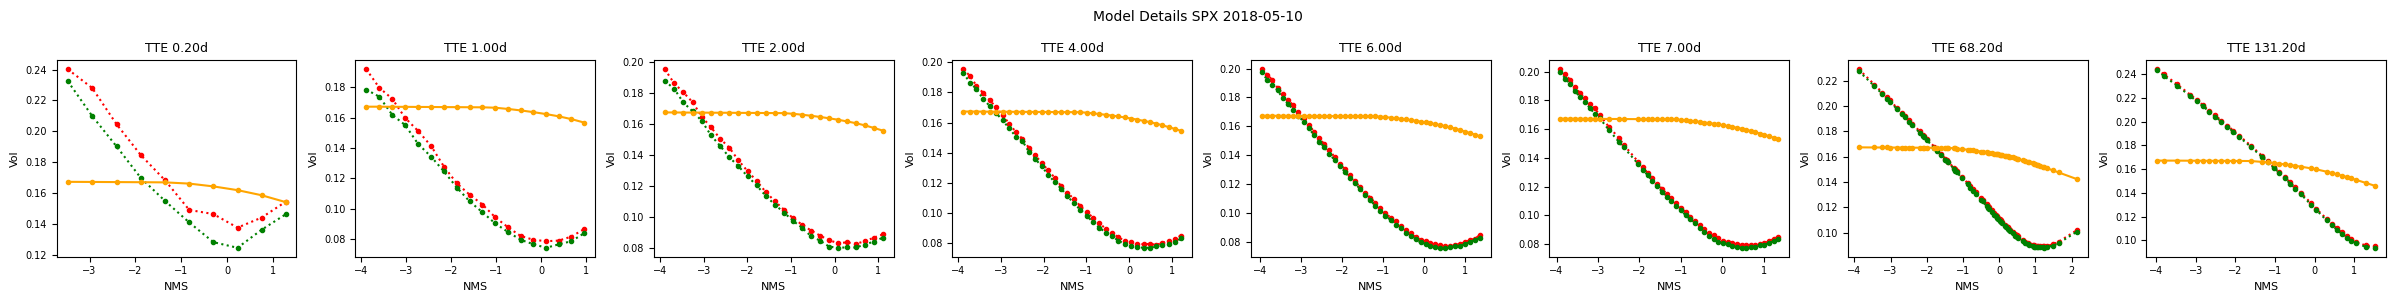

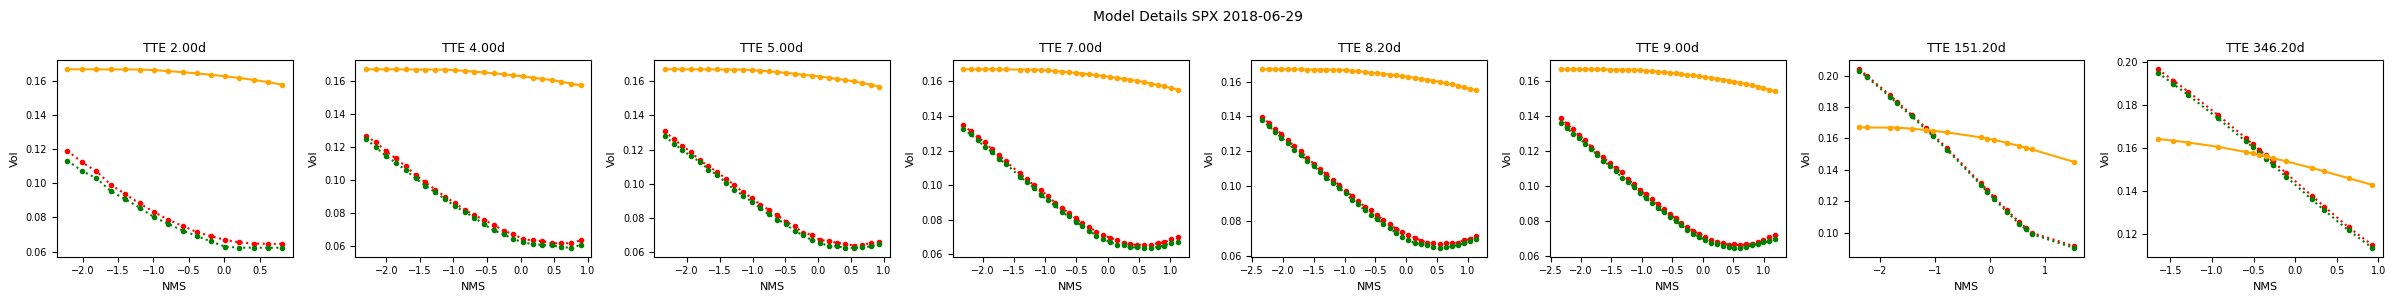

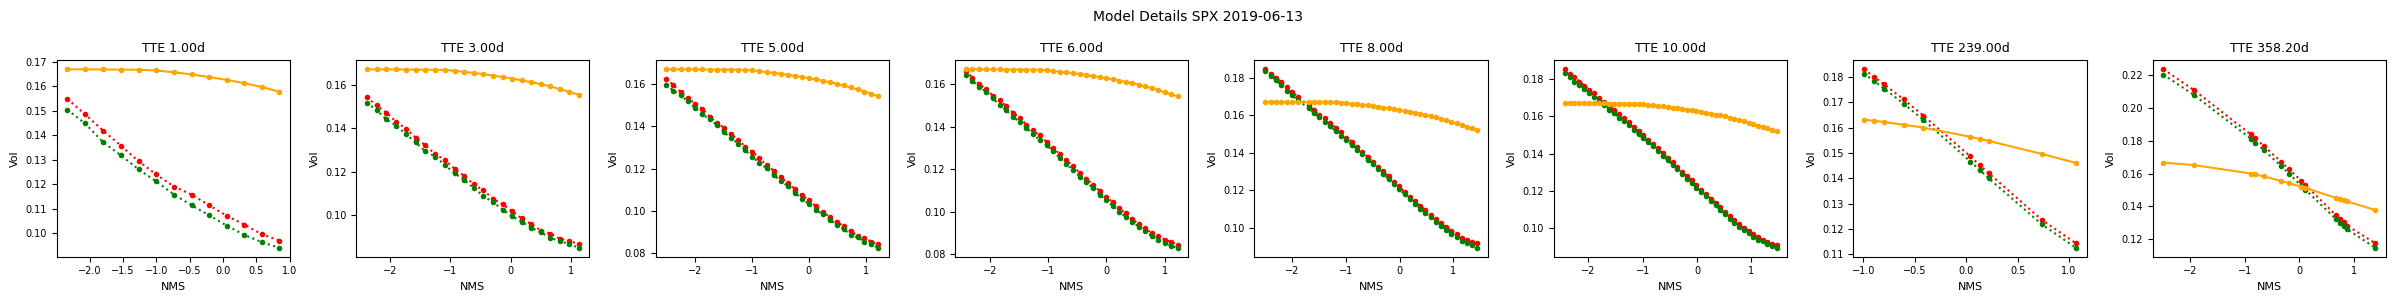

00: Training 'train_vol_vol_attn' epoch 2/1000 error avg trn 663.2; val 403.6/883 [8s 0.7s 0.35s]. LR: 1.00e-03, GN 415.4, excess_weighted: 0.03673/0.045, excess_weighted_avg: 0.03502/0.0446, excess_spread: 534.9/932.7, excess_spread_avg: 504.7/932.7, excess: 0.04482/0.05771, excess_avg: 0.04441/0.05771. ETA: 3:36:58.
00: Training 'train_vol_vol_attn' epoch 3/1000 error avg trn 386.7; val 208.9/490.3 [12s 0.7s 0.35s]. LR: 1.00e-03, GN 307.5, excess_weighted: 0.01834/0.0248, excess_weighted_avg: 0.0171/0.02427, excess_spread: 267.1/514, excess_spread_avg: 251.7/514, excess: 0.02187/0.03104, excess_avg: 0.02171/0.03104. ETA: 5:32:23.
00: Training 'train_vol_vol_attn' epoch 4/1000 error avg trn 208; val 69.32/180 [16s 0.7s 0.35s]. LR: 1.00e-03, GN 150.8, excess_weighted: 0.005664/0.008946, excess_weighted_avg: 0.005494/0.008572, excess_spread: 82.5/185.4, excess_spread_avg: 77.49/185.4, excess: 0.006882/0.01025, excess_avg: 0.006761/0.01025. ETA: 7:28:15.
00: Training 'train_vol_vol_attn'

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = GatingDecoderFactory(
        num_head = 16,
        num_QK = 4,        
        V_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',    
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 4, # equal QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',
        )
    ),
)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 10, debug=False, val_batch_size=256 )
